In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib widget

In [2]:
import time
from functools import partial
from multiprocessing import Pool

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Pretty, display
from scipy.optimize import differential_evolution

import geodesiq as gq

In [3]:
# Model and worker code live in four_level.py so spawned worker processes can import them
import four_level as fls
from four_level import build_model

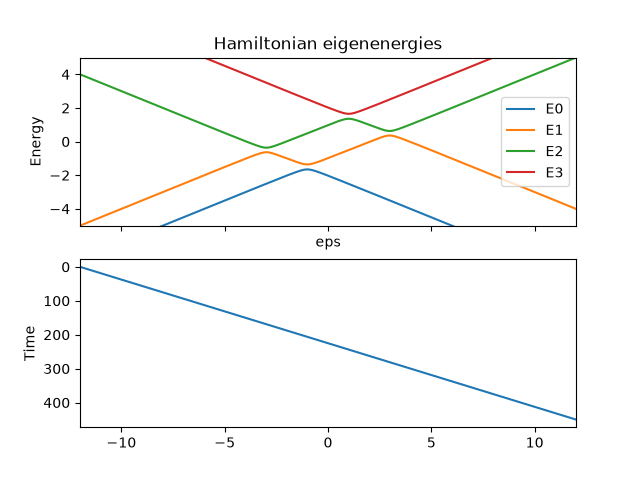

In [4]:
# ----- Set system and control parameters -----
alpha, beta = 0, 0
dia_alpha, dia_beta = 0, 0

DeltaL = 1
phiL = 0.1
phiR = np.pi / 2

tc = 0.2 * DeltaL
DeltaR = 2 * DeltaL

# tc = 0.1 * DeltaL
# DeltaR = 5 * DeltaL

tee = tc / 2 * (1 + np.exp(1j * (phiL - phiR)))
teg = tc / 2 * (np.exp(1j * phiL) - np.exp(1j * phiR))

eps0, epsf = -12 * DeltaL, 12 * DeltaL
MODEL_PARAMS = dict(
    DeltaL=DeltaL,
    DeltaR=DeltaR,
    tee=tee,
    teg=teg,
    eps0=eps0,
    epsf=epsf,
    alpha=alpha,
    beta=beta,
    dia_alpha=dia_alpha,
    dia_beta=dia_beta,
)
model = build_model(**MODEL_PARAMS)

fig, axs = plt.subplots(2, sharex=True)
model.plot_eigenvalues(ax=axs[0])
axs[0].set_ylim(-5, 5)
axs[0].set_xlim(-12, 12)

model.set_control(alpha=alpha, beta=beta, dia_alpha=dia_alpha, dia_beta=dia_beta)
pulse = model.synthesize_pulse(450)
axs[1].plot(pulse.pulse, pulse.times)
axs[1].set_ylim(*axs[1].get_ylim()[::-1])
axs[1].set_ylabel("Time");


interactive(children=(FloatSlider(value=0.0, description='alpha', max=5.0, min=-5.0), FloatSlider(value=0.0, d…

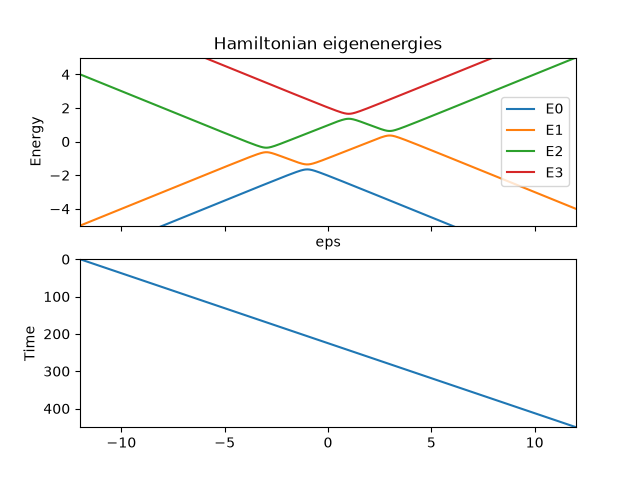

In [5]:
import ipywidgets as widgets

# ----- Interactive exploration of the exponents -----
# Separate model so the sliders do not modify `model` used in the cells below
slider_model = build_model(**MODEL_PARAMS)
slider_duration = 450

fig_s, axs_s = plt.subplots(2, sharex=True)
slider_model.plot_eigenvalues(ax=axs_s[0])
axs_s[0].set_ylim(-5, 5)
axs_s[0].set_xlim(-12, 12)

(pulse_line,) = axs_s[1].plot([], [])
axs_s[1].set_ylim(slider_duration, 0)
axs_s[1].set_ylabel("Time")


def update_pulse(alpha, beta, dia_alpha, dia_beta):
    try:
        slider_model.set_control(alpha=alpha, beta=beta, dia_alpha=dia_alpha, dia_beta=dia_beta)
        pulse = slider_model.synthesize_pulse(slider_duration)
        pulse_line.set_data(pulse.pulse, pulse.times)
        axs_s[1].set_title("")
    except Exception as e:
        pulse_line.set_data([], [])
        axs_s[1].set_title(f"Failed: {e}", fontsize=8)
    fig_s.canvas.draw_idle()


slider_kw = dict(min=-5, max=5, step=0.1)
widgets.interact(
    update_pulse,
    alpha=widgets.FloatSlider(value=alpha, description="alpha", **slider_kw),
    beta=widgets.FloatSlider(value=beta, description="beta", **slider_kw),
    dia_alpha=widgets.FloatSlider(value=dia_alpha, description="dia_alpha", **slider_kw),
    dia_beta=widgets.FloatSlider(value=dia_beta, description="dia_beta", **slider_kw),
);

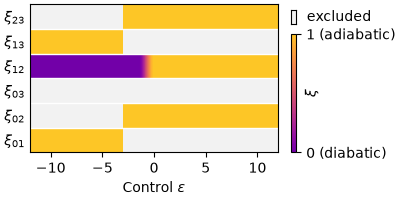

In [6]:
from matplotlib.colors import ListedColormap

# Reversed, trimmed plasma: monotonic lightness
cmap = ListedColormap(plt.get_cmap("plasma_r")(np.linspace(0.78, 0.12, 256)), name="dia_ad")
DIABATIC_COLOR, ADIABATIC_COLOR = cmap(1.0), cmap(0.0)

bad_color = "0.95"  # very light gray: lighter than any colormap value, also in grayscale
cmap = cmap.with_extremes(bad=bad_color)

dia_list = model._dia_list.dense()  # (n_points, 4, 4); the model stores only the transitions of the occupied state
pairs = [(i, j) for i in range(4) for j in range(i + 1, 4)]
matrix = np.ma.masked_less([dia_list[:, i, j] for i, j in pairs], 0)  # copy; masked -> drawn as "bad"
labels = [rf"$\xi_{{{i}{j}}}$" for i, j in pairs]

fig, ax = plt.subplots(figsize=(4, 2), layout="constrained")
im = ax.imshow(
    matrix, extent=(eps0, epsf, 0, len(pairs)), aspect="auto", origin="lower", cmap=cmap, interpolation="none"
)
ax.set_yticks(np.arange(len(labels)) + 0.5, labels)
ax.tick_params(axis="y", length=0)
for y in range(1, len(labels)):
    ax.axhline(y, color="white", linewidth=1)
ax.set_xlabel(r"Control $\epsilon$")

# Colorbar, shortened to leave room for a swatch of the "bad" color on top
cbar = fig.colorbar(im, ax=ax, shrink=0.8, anchor=(0.0, 0.0))
cbar.ax.set_yticks([0, 1])
cbar.ax.set_yticklabels(["0 (diabatic)", "1 (adiabatic)"])
cbar.set_label(r"$\xi$", labelpad=-65)
bad_ax = cbar.ax.inset_axes([0, 1.08, 1, 0.12])
bad_ax.set_facecolor(bad_color)
bad_ax.set_xticks([])
bad_ax.set_yticks([])
bad_ax.text(1.4, 0.5, "  excluded", transform=bad_ax.transAxes, va="center", ha="left");

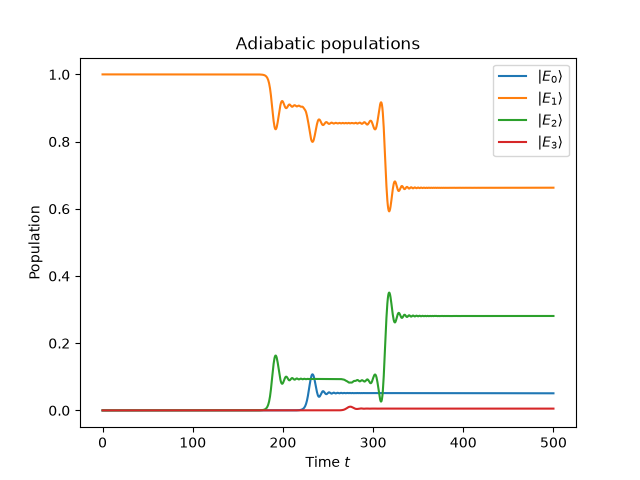

In [7]:
dynamics = gq.Dynamics(model, 500)

dynamics.plot_populations(basis="adiabatic");


In [ ]:
# ---------------------------------------------------------------- EDIT ---
DURATION = 500  # total time, used unless "duration" is in BOUNDS
BOUNDS = {  # optimised `set_control` parameters, plus optionally "duration"
    "alpha": (-10, 10),
    "beta": (-10, 10),
    "dia_alpha": (-10, 10),
    "dia_beta": (-10, 10),
    "duration": (100, 1000),  # uncomment to optimise the total time too
}
# -------------------------------------------------------------------------
PARAM_NAMES = list(BOUNDS)
# Picklable, so DE can evaluate it in worker processes ("spawn" on Windows)
objective = partial(fls.infidelity, model_params=MODEL_PARAMS, param_names=PARAM_NAMES, duration=DURATION)
# Initial guess: the control parameters in MODEL_PARAMS, run for DURATION
x_guess = [DURATION if n == "duration" else MODEL_PARAMS[n] for n in PARAM_NAMES]
# Fidelity of the initial guess, best of the initial population, then of every generation
fidelity_epochs = [1 - objective(x_guess)]


def recording_map(pool):
    """Map for DE `workers`: its first call evaluates the initial population, whose best is stored."""

    def map_(func, iterable):
        energies = pool.map(func, iterable)
        if len(fidelity_epochs) == 1:
            fidelity_epochs.append(1 - min(energies))
        return energies

    return map_


class Progress:
    """scipy callback: shows the current best point in place and keeps it in case of an interrupt."""

    def __init__(self, label):
        self.label, self.t0, self.it, self.best = label, time.perf_counter(), 0, None
        self.handle = display(Pretty(f"[{label}] waiting"), display_id=True)

    def __call__(self, intermediate_result):  # name must be exactly this
        fidelity_epochs.append(1 - intermediate_result.fun)
        self.it += 1
        self.best = r = intermediate_result
        params = "  ".join(f"{n}={v:.6g}" for n, v in zip(PARAM_NAMES, r.x, strict=False))
        elapsed = time.perf_counter() - self.t0
        self.handle.update(
            Pretty(f"[{self.label}]  iteration {self.it}   {elapsed:.1f}s   1-F = {r.fun:.3e}\n{params}")
        )


def print_result(title, res):
    print(f"\n=== {title} ===\nFidelity   = {1 - res.fun:.12f}\nInfidelity = {res.fun:.3e}")
    for n, v in zip(PARAM_NAMES, res.x, strict=False):
        print(f"  {n:10s} = {v:.10g}")


def interrupted(*progress):
    print("Interrupted, keeping best point so far.")
    return min((p.best for p in progress if p.best is not None), key=lambda r: r.fun)


# ------------------------------------------------------- global search ---
de_progress = Progress("DE")
try:
    with Pool() as pool:  # one process per core
        res = differential_evolution(
            objective,
            list(BOUNDS.values()),
            popsize=16,
            maxiter=200,
            tol=1e-10,
            polish=False,
            updating="deferred",
            workers=recording_map(pool),
            callback=de_progress,
            seed=0,
        )
    print_result(f"DE ({res.nfev} evals, {res.message})", res)
except KeyboardInterrupt:
    res = interrupted(de_progress)

x_best = res.x
best = dict(zip(PARAM_NAMES, x_best, strict=False))
duration_best = best.pop("duration", DURATION)
print_result("FINAL", res)

[DE]  iteration 73   20.8s   1-F = 5.316e-03
alpha=3.75753  beta=2.76471  dia_alpha=-7.00455  dia_beta=9.0395  duration=158.469

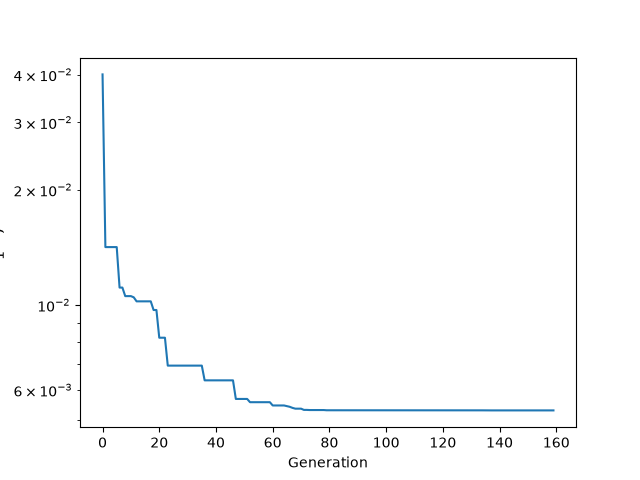

In [12]:
fig, ax = plt.subplots()

ax.plot(np.arange(-1, len(fidelity_epochs) - 1), 1 - np.array(fidelity_epochs))  # -1: initial guess
ax.set_yscale("log")
ax.set_xlabel("Generation")
ax.set_ylabel(r"$1 - \mathcal{F}$");

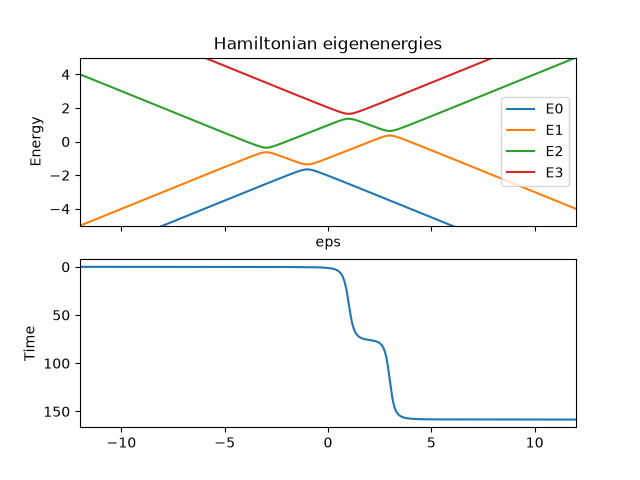

In [14]:
fig, axs = plt.subplots(2, sharex=True)
model.plot_eigenvalues(ax=axs[0])
axs[0].set_ylim(-5, 5)
axs[0].set_xlim(-12, 12)

model.set_control(**best)
pulse = model.synthesize_pulse(duration_best)
axs[1].plot(pulse.pulse, pulse.times)
axs[1].set_ylim(*axs[1].get_ylim()[::-1])
axs[1].set_ylabel("Time");

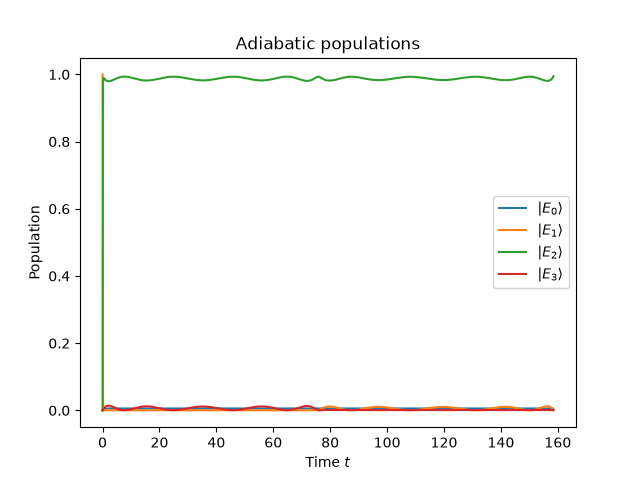

In [15]:
dynamics = gq.Dynamics(model, duration_best)

fig, ax = dynamics.plot_populations(basis="adiabatic")
# ax.set_yscale('log')
# ax.set_ylim(1e-6, 2)

In [20]:
# ------------------------------------------------------ data for the main figure ---
# Everything needed to compose the figure in another notebook: spectrum and ξ along the path of the DE optimum
# (left panels), pulses of the initial guess and of the optimum plus the DE convergence (upper right), and the
# populations of the optimum versus the instantaneous detuning (lower right)
import json
from pathlib import Path

FIGURE_DATA = Path("data/four_level_main_figure.npz")
PLOT_ACCURACY = 20000  # dense pulse grid: the optimised ramp at t ~ 0 is very steep


def solved_model(controls):
    m = build_model(**MODEL_PARAMS)
    m.set_control(**controls)
    m.solve_problem(pulse_accuracy=PLOT_ACCURACY)
    return m


guess = dict(zip(PARAM_NAMES, x_guess, strict=True))
duration_guess = guess.pop("duration", DURATION)
controls = {"guess": (guess, duration_guess), "best": (best, duration_best)}

data = dict(
    DeltaL=DeltaL,
    DeltaR=DeltaR,
    tee=tee,
    teg=teg,
    eps0=eps0,
    epsf=epsf,
    controls=json.dumps(
        {k: {**{n: float(v) for n, v in c.items()}, "duration": float(T)} for k, (c, T) in controls.items()}
    ),
    generation=np.arange(-1, len(fidelity_epochs) - 1),  # -1: initial guess, 0: best of the initial population
    infid_epochs=1 - np.array(fidelity_epochs),
)

# Spectrum, ξ and the occupied eigenstate along the sweep of the optimum
m = solved_model(best)
x, dia_list = m.control_pulse, m._dia_list.dense()  # (n_points, 4, 4), the layout stored in the figure data
occ = np.argmax((dia_list >= 0).sum(axis=2), axis=1)  # index of the occupied eigenstate
data.update(
    x=x,
    E=np.real(m.eigenenergies),
    dia_list=dia_list,  # ξ_ij(ε), negative = excluded
    occ=occ,
    adfrac=np.array([row[row >= 0].min() for row in dia_list[np.arange(len(x)), occ]]),  # 0 diabatic, 1 adiabatic
    dia_levels=np.stack(
        [x / 2 + DeltaL, x / 2 - DeltaL, -x / 2 + DeltaR, -x / 2 - DeltaR], axis=1
    ),  # |L,e>,|L,g>,|R,e>,|R,g>
)

# Pulses and populations (columns: diabatic |L,e>,|L,g>,|R,e>,|R,g>; adiabatic ψ_0..ψ_3)
for label, (c, T) in controls.items():
    dyn = gq.Dynamics(m if label == "best" else solved_model(c), T)
    data.update(
        {
            f"t_{label}": dyn.times,
            f"eps_{label}": dyn.pulse,
            f"Pd_{label}": dyn.populations(basis="diabatic"),
            f"Pa_{label}": dyn.populations(basis="adiabatic"),
            f"infid_{label}": 1 - dyn.state_fidelity(),
        }
    )

FIGURE_DATA.parent.mkdir(exist_ok=True)
np.savez_compressed(FIGURE_DATA, **data)
print(f"Saved {FIGURE_DATA}: 1-F guess = {data['infid_guess']:.3e}, best = {data['infid_best']:.3e}")

Saved data\four_level_main_figure.npz: 1-F guess = 7.190e-01, best = 5.389e-03
